Data successfully loaded from /var/housing.csv
Feature engineering completed!
X shape: (20640, 14)


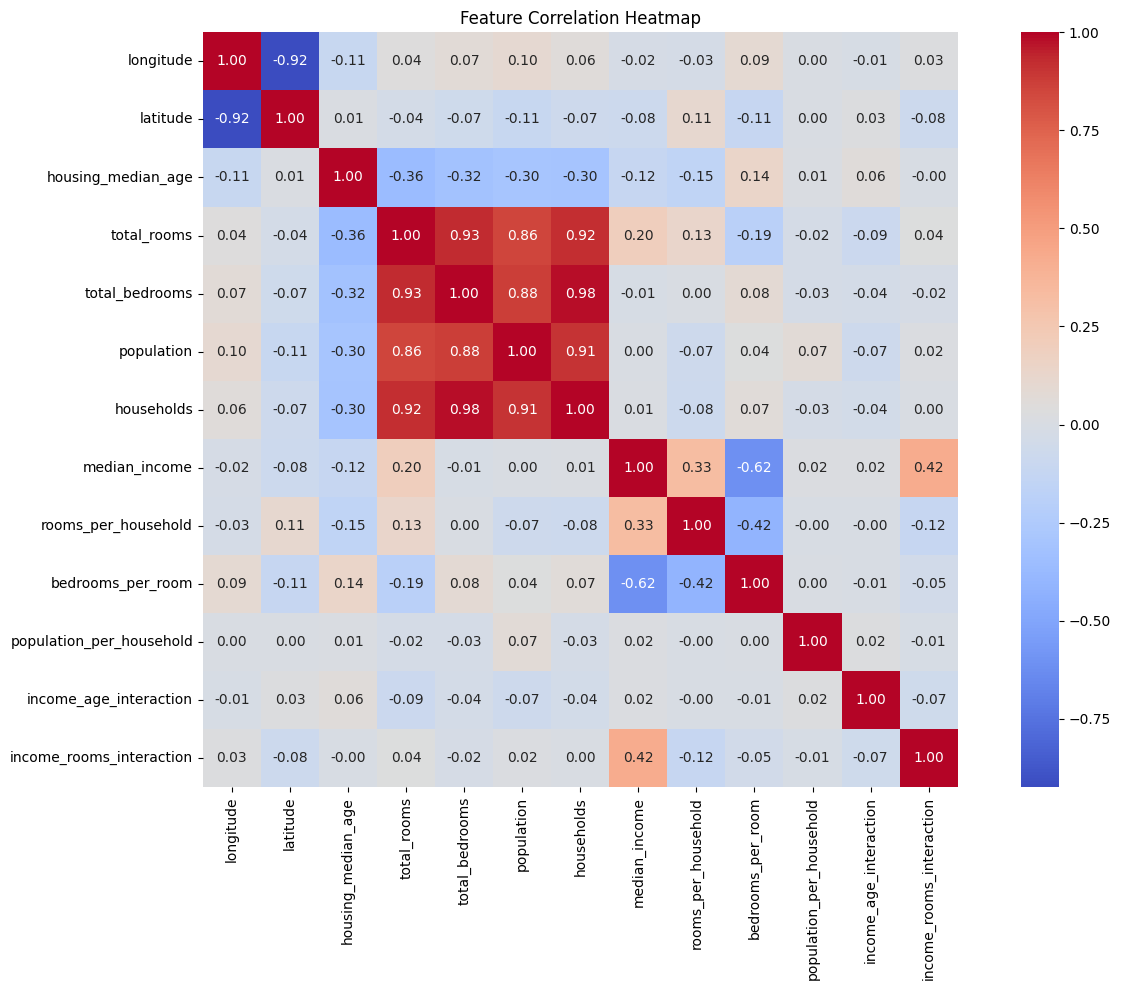

Preprocessing completed successfully!
Training shape: (16512, 18)
Testing shape: (4128, 18)
Best Ridge alpha: {'alpha': 1}
Best Lasso alpha: {'alpha': 1}

--- OLS Results ---
RMSE: 68,845.00 | MAE: 49,458.67 | R²: 0.6383

--- Ridge (L2) Results ---
RMSE: 68,853.33 | MAE: 49,465.15 | R²: 0.6382

--- Lasso (L1) Results ---
RMSE: 68,846.19 | MAE: 49,459.60 | R²: 0.6383


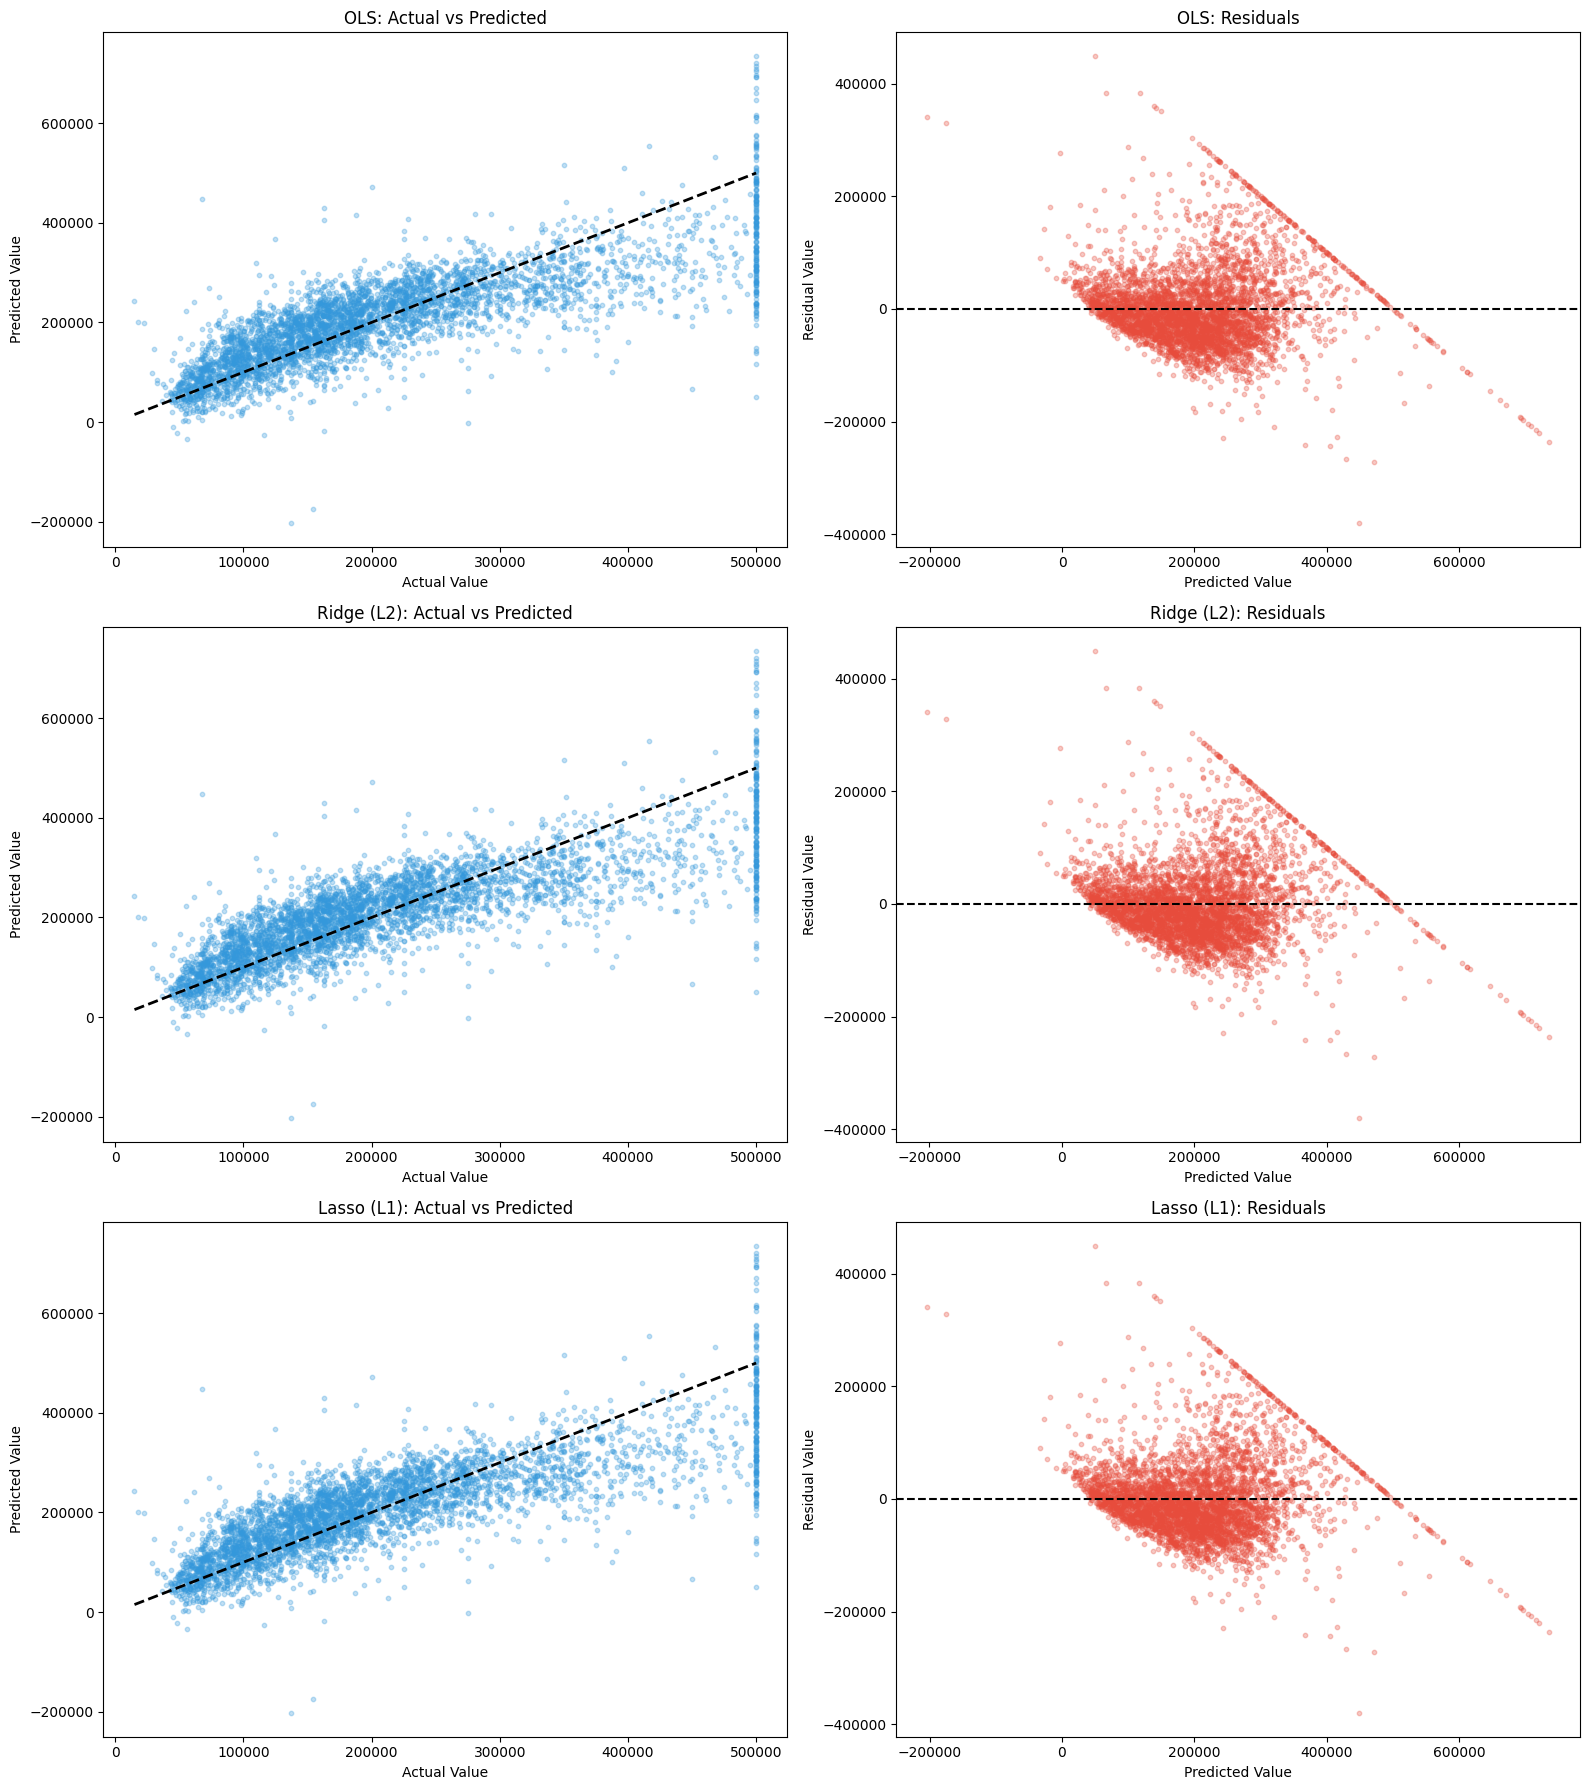


--- Model Performance Comparison ---
     Model     RMSE      MAE  R² Score
       OLS 68845.00 49458.67    0.6383
Ridge (L2) 68853.33 49465.15    0.6382
Lasso (L1) 68846.19 49459.60    0.6383


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import os

# --- STEP 1: LOAD DATA ---
if os.path.exists('/var/housing.csv'):
    df = pd.read_csv('/var/housing.csv')
    print("Data successfully loaded from /var/housing.csv")
else:
    from sklearn.datasets import fetch_california_housing
    data = fetch_california_housing(as_frame=True)
    df = data.frame
    df["median_house_value"] = df["median_house_value"] * 100_000
    print("Loaded fallback dataset (sklearn version)")

# --- STEP 2: FEATURE ENGINEERING ---

# Create ratio features
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

# Create centered interaction features
income_centered = df["median_income"] - df["median_income"].mean()
age_centered = df["housing_median_age"] - df["housing_median_age"].mean()
rooms_centered = df["rooms_per_household"] - df["rooms_per_household"].mean()

df["income_age_interaction"] = income_centered * age_centered
df["income_rooms_interaction"] = income_centered * rooms_centered

# Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Feature engineering completed!")
print("X shape:", X.shape)

# --- STEP 3: CORRELATION HEATMAP ---

X_numeric = X.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))
sns.heatmap(
    X_numeric.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# --- STEP 4: TRAIN/TEST SPLIT AND PREPROCESSING ---

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform test data
X_test_scaled = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

# --- STEP 5: TRAIN & TUNE MODELS ---
# 1. OLS (Baseline)
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

# 2. Ridge (L2)
ridge_gs = GridSearchCV(
    Ridge(), {"alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5, scoring="neg_mean_squared_error"
)
ridge_gs.fit(X_train_scaled, y_train)
best_ridge = ridge_gs.best_estimator_

# 3. Lasso (L1)
lasso_gs = GridSearchCV(
    Lasso(max_iter=100000, tol=0.001),
    {"alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

lasso_gs.fit(X_train_scaled, y_train)
best_lasso = lasso_gs.best_estimator_

print(f"Best Ridge alpha: {ridge_gs.best_params_}")
print(f"Best Lasso alpha: {lasso_gs.best_params_}")

# --- STEP 6: EVALUATE & PLOT RESULTS ---
models = {"OLS": ols, "Ridge (L2)": best_ridge, "Lasso (L1)": best_lasso}
results = []
fig, axs = plt.subplots(3, 2, figsize=(16, 18))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)
    residuals = y_test - y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append([name, round(rmse, 2), round(mae, 2), round(r2, 4)])

    print(f"\n--- {name} Results ---\nRMSE: {rmse:,.2f} | MAE: {mae:,.2f} | R²: {r2:.4f}")

    # Plot Actual vs Predicted
    axs[i, 0].scatter(y_test, y_pred, alpha=0.3, s=10, color='#3498db')
    axs[i, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
    axs[i, 0].set_title(f"{name}: Actual vs Predicted")
    axs[i, 0].set_xlabel("Actual Value")
    axs[i, 0].set_ylabel("Predicted Value")

    # Plot Residuals
    axs[i, 1].scatter(y_pred, residuals, alpha=0.3, s=10, color='#e74c3c')
    axs[i, 1].axhline(y=0, color='k', linestyle='--')
    axs[i, 1].set_title(f"{name}: Residuals")
    axs[i, 1].set_xlabel("Predicted Value")
    axs[i, 1].set_ylabel("Residual Value")

plt.tight_layout()
plt.show()

# Print Final Comparison Table
results_df = pd.DataFrame(results, columns=["Model", "RMSE", "MAE", "R² Score"])
print("\n--- Model Performance Comparison ---")
print(results_df.to_string(index=False))

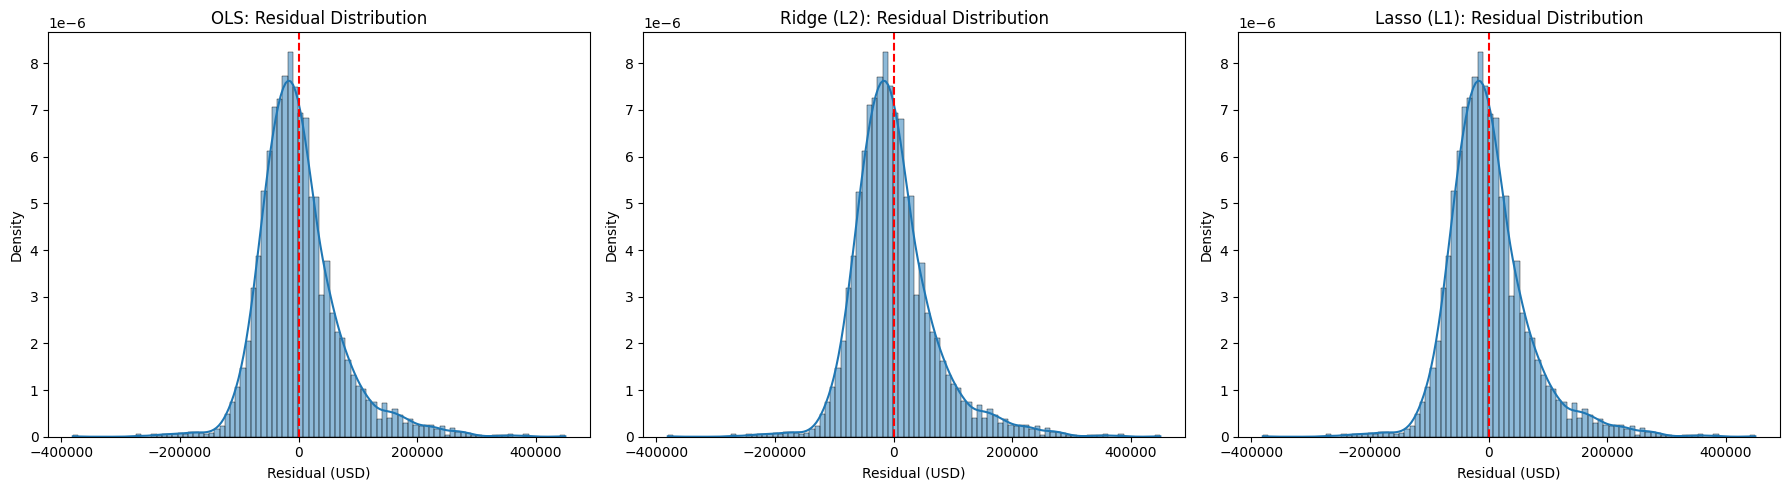

In [ ]:
# STEP 7: RESIDUAL DISTRIBUTION CURVES

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    residuals = y_test - y_pred

    sns.histplot(
        residuals,
        kde=True,
        stat="density",
        ax=ax
    )

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual (USD)")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

In [ ]:
# --- VIF ANALYSIS ---
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical features
X_vif = X.select_dtypes(include=np.number).copy()

# Replace infinite values and handle missing values
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)
X_vif = X_vif.fillna(X_vif.median())

# Remove constant columns, if any
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

# Standardize features for numerical stability
X_vif_scaled = StandardScaler().fit_transform(X_vif)

# Calculate VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif_scaled, i)
    for i in range(X_vif_scaled.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)

print(vif_data.to_string(index=False))

                 Feature       VIF
          total_bedrooms 34.372140
              households 34.072471
             total_rooms 17.940696
                latitude  9.584856
               longitude  9.243571
              population  6.708393
           median_income  2.859916
       bedrooms_per_room  2.759255
     rooms_per_household  1.738023
income_rooms_interaction  1.463076
      housing_median_age  1.265665
  income_age_interaction  1.067136
population_per_household  1.066585


In [ ]:
# --- CHECK NUMERICAL DATA BEFORE VIF ---

print("Missing values:")
print(X_numeric.isna().sum())

print("\nInfinite values:")
print(np.isinf(X_numeric).sum())

print("\nConstant columns:")
print(X_numeric.columns[X_numeric.nunique() <= 1].tolist())

print("\nData types:")
print(X_numeric.dtypes)

Missing values:
longitude                     0
latitude                      0
housing_median_age            0
total_rooms                   0
total_bedrooms              207
population                    0
households                    0
median_income                 0
rooms_per_household           0
bedrooms_per_room           207
population_per_household      0
income_age_interaction        0
income_rooms_interaction      0
dtype: int64

Infinite values:
longitude                   0
latitude                    0
housing_median_age          0
total_rooms                 0
total_bedrooms              0
population                  0
households                  0
median_income               0
rooms_per_household         0
bedrooms_per_room           0
population_per_household    0
income_age_interaction      0
income_rooms_interaction    0
dtype: int64

Constant columns:
[]

Data types:
longitude                   float64
latitude                    float64
housing_median_age         

In [ ]:
# STEP: CREATE INTERACTION FEATURES

df["income_age_interaction"] = (
    df["median_income"] * df["housing_median_age"]
)

df["income_rooms_interaction"] = (
    df["median_income"] * df["rooms_per_household"]
)

print("Interaction features created successfully!")

Interaction features created successfully!


In [ ]:
# Create the feature matrix X and target y

df_encoded = pd.get_dummies(
    df, columns=["ocean_proximity"], drop_first=True
)

X = df_encoded.drop("median_house_value", axis=1)
y = df_encoded["median_house_value"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", X.columns.tolist())

X shape: (20640, 17)
y shape: (20640,)
Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_age_interaction', 'income_rooms_interaction', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [ ]:
# Center variables before creating interaction terms

income_centered = df["median_income"] - df["median_income"].mean()
age_centered = df["housing_median_age"] - df["housing_median_age"].mean()
rooms_centered = df["rooms_per_household"] - df["rooms_per_household"].mean()

df["income_age_interaction"] = income_centered * age_centered

df["income_rooms_interaction"] = income_centered * rooms_centered

print("Centered interaction features created!")

Centered interaction features created!


In [ ]:
df_encoded = pd.get_dummies(
    df, columns=["ocean_proximity"], drop_first=True
)

X = df_encoded.drop("median_house_value", axis=1)
y = df_encoded["median_house_value"]

print("X shape:", X.shape)
print("Features:", X.columns.tolist())

X shape: (20640, 17)
Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_age_interaction', 'income_rooms_interaction', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
